## Phase 1 — Data Exploration & Understanding

Dataset: NASA Exoplanet Archive, PSCompPars table, downloaded 2026-07-15.
Total rows: 6319, columns: 84.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from scipy.stats import pearsonr

from pathlib import Path

def find_data_dir():
    """Locate the project's data/ folder from anywhere inside the project tree."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "data").is_dir():
            return p / "data"
    raise FileNotFoundError("Could not locate the project's data/ folder")

DATA = find_data_dir()

df = pd.read_csv(DATA / "raw_nasa_archive_2026-07-15.csv", comment="#")

In [2]:
print(df.shape)
df.head()

(6319, 84)


,pl_name,hostname,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,pl_controv_flag,pl_orbper,pl_orbpererr1,...,sy_disterr2,sy_vmag,sy_vmagerr1,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2
0,11 Com b,11 Com,2,1,Radial Velocity,2007,Xinglong Station,0,323.21000,0.06,...,-1.9238,4.72307,0.023,-0.023,2.282,0.346,-0.346,4.44038,0.003848,-0.003848
1,11 UMi b,11 UMi,1,1,Radial Velocity,2009,Thueringer Landessternwarte Tautenburg,0,516.21997,3.20,...,-1.9765,5.01300,0.005,-0.005,1.939,0.270,-0.270,4.56216,0.003903,-0.003903
2,14 And b,14 And,1,1,Radial Velocity,2008,Okayama Astrophysical Observatory,0,186.76000,0.11,...,-0.7140,5.23133,0.023,-0.023,2.331,0.240,-0.240,4.91781,0.002826,-0.002826
3,14 Her b,14 Her,1,2,Radial Velocity,2002,W. M. Keck Observatory,0,1766.41000,0.67,...,-0.0073,6.61935,0.023,-0.023,4.714,0.016,-0.016,6.38300,0.000351,-0.000351
4,16 Cyg B b,16 Cyg B,3,1,Radial Velocity,1996,Multiple Observatories,0,798.50000,1.00,...,-0.0111,6.21500,0.016,-0.016,4.651,0.016,-0.016,6.06428,0.000603,-0.000603


In [3]:
print(df.columns.tolist())

['pl_name', 'hostname', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'pl_controv_flag', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_logg', 'st_loggerr1', 'st_loggerr2', 'st_logglim', 'rastr', 'ra',

In [4]:
print("Duplicate pl_name entries:", df['pl_name'].duplicated().sum())
print(df[df['pl_name'].duplicated(keep=False)].sort_values('pl_name')[['pl_name','hostname','discoverymethod','pl_rade']])

Duplicate pl_name entries: 0
Empty DataFrame
Columns: [pl_name, hostname, discoverymethod, pl_rade]
Index: []


In [5]:
df[['pl_rade','pl_orbper','pl_bmasse','st_teff','st_rad','st_mass']].describe()

,pl_rade,pl_orbper,pl_bmasse,st_teff,st_rad,st_mass
count,6269.000000,5.976000e+03,6288.000000,6022.000000,5998.000000,6310.000000
mean,5.837761,7.163541e+04,403.582767,5393.832097,1.489763,0.934440
std,5.416538,5.202642e+06,1136.703937,1729.857863,3.870046,0.387214
min,0.309800,9.070629e-02,0.020000,415.000000,0.011500,0.009400
25%,1.840000,4.308908e+00,4.300000,4898.000000,0.770000,0.770000
50%,2.857000,1.077345e+01,9.270000,5544.000000,0.950000,0.940000
75%,11.900000,3.851858e+01,189.102962,5897.240000,1.245000,1.083750
max,87.205870,4.020000e+08,9534.852210,57000.000000,88.475000,9.100000


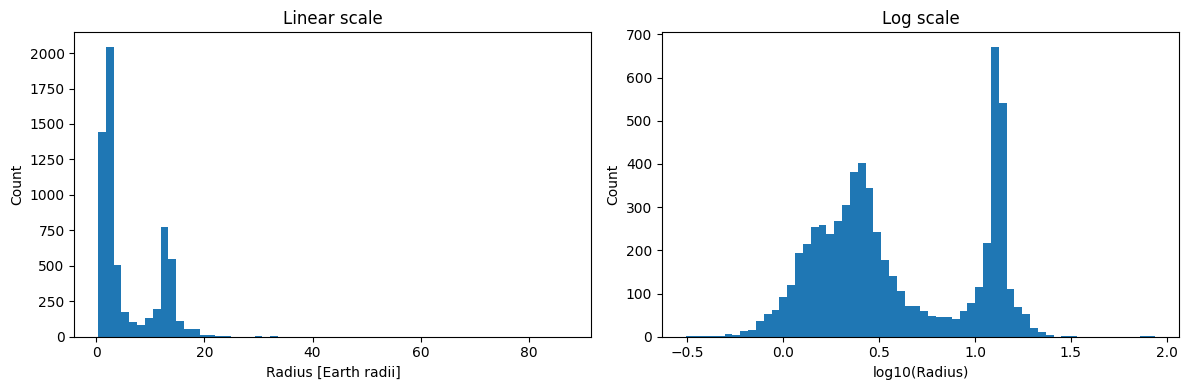

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['pl_rade'].dropna(), bins=60)
axes[0].set_xlabel('Radius [Earth radii]')
axes[0].set_ylabel('Count')
axes[0].set_title('Linear scale')

axes[1].hist(np.log10(df['pl_rade'].dropna()), bins=60)
axes[1].set_xlabel('log10(Radius)')
axes[1].set_ylabel('Count')
axes[1].set_title('Log scale')

plt.tight_layout()
plt.show()

In [7]:
print("Total dataset size:", df.shape)

print("\nPlanets with radius > 30 Earth radii (likely not real planets):")
print(df.loc[df['pl_rade'] > 30, ['pl_name','pl_rade','pl_bmasse','discoverymethod']])

Total dataset size: (6319, 84)

Planets with radius > 30 Earth radii (likely not real planets):
           pl_name   pl_rade   pl_bmasse discoverymethod
142       DH Tau b  30.26430  3496.00000         Imaging
361       GQ Lup b  33.60000  6356.00000         Imaging
522    HD 100546 b  77.34210  2701.54146         Imaging
3796  Kepler-297 d  32.60000         NaN         Transit
6049   V2376 Ori b  87.20587  6356.56814         Imaging


### Key findings from initial exploration

- Radius distribution is strongly right-skewed (mean 5.84 R⊕ vs median 2.86 R⊕) → work in log10(radius).
- Linear/log histograms show a large valley around 7-9 R⊕ (hot-Jupiter pile-up) — **not** the Fulton radius gap, which is a finer feature expected around 1.5-2.0 R⊕.
- 5 planets have radius > 30 R⊕ (mostly Imaging-detected, near the planet/brown-dwarf mass boundary) — automatically excluded once the 0.5-4 R⊕ filter is applied.

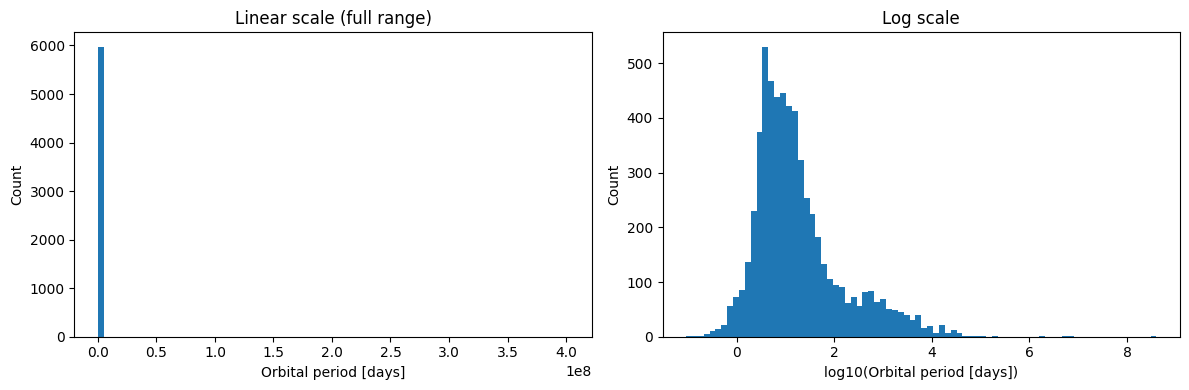

count    5.976000e+03
mean     7.163541e+04
std      5.202642e+06
min      9.070629e-02
25%      4.308908e+00
50%      1.077345e+01
75%      3.851858e+01
max      4.020000e+08
Name: pl_orbper, dtype: float64


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['pl_orbper'].dropna(), bins=80)
axes[0].set_xlabel('Orbital period [days]')
axes[0].set_ylabel('Count')
axes[0].set_title('Linear scale (full range)')

axes[1].hist(np.log10(df['pl_orbper'].dropna()), bins=80)
axes[1].set_xlabel('log10(Orbital period [days])')
axes[1].set_ylabel('Count')
axes[1].set_title('Log scale')

plt.tight_layout()
plt.show()

print(df['pl_orbper'].describe())

### Orbital period distribution

- Linear-scale histogram is uninformative: a single extreme outlier (~4.02×10⁸ days, an Imaging-detected wide-orbit planet) forces the axis scale to compress all realistic values into one bar. **Lesson: always plot orbital period in log scale.**
- Log-scale histogram shows a sharp peak around 5-6 days, and a long right tail extending to very wide orbits.
- Summary statistics: median = 10.77 days, 25th percentile = 4.31 days, 75th percentile = 38.5 days. Half of all planets with known period orbit in under 11 days.
- This concentration near short periods reflects **detection bias**, not the true population: short-period planets transit more frequently (easier to catch within a limited observing baseline) and produce a larger radial-velocity signal.
- Note: the natural median (~10.8 days) closely matches the 10-day threshold suggested for the short/long period split in the Bayesian section — a useful cross-check.

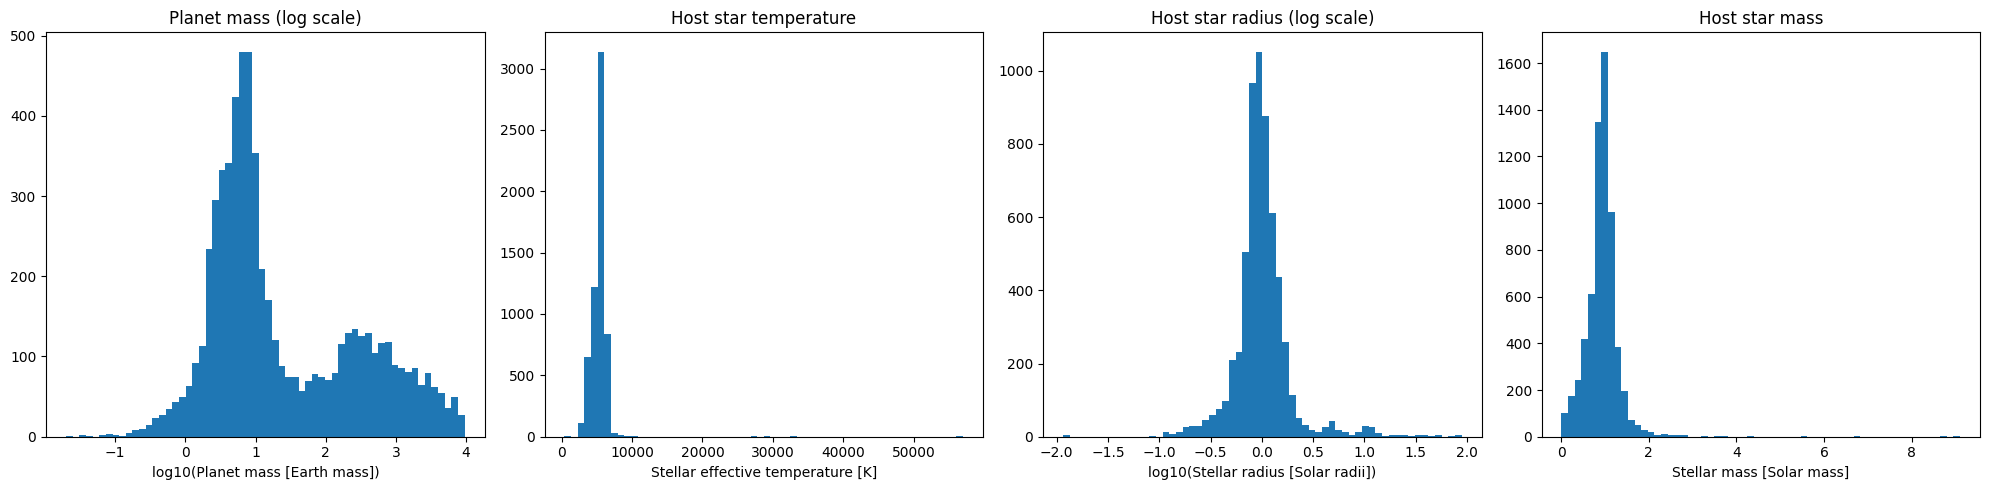

,pl_bmasse,st_teff,st_rad,st_mass
count,6288.000000,6022.000000,5998.000000,6310.000000
mean,403.582767,5393.832097,1.489763,0.934440
std,1136.703937,1729.857863,3.870046,0.387214
min,0.020000,415.000000,0.011500,0.009400
25%,4.300000,4898.000000,0.770000,0.770000
50%,9.270000,5544.000000,0.950000,0.940000
75%,189.102962,5897.240000,1.245000,1.083750
max,9534.852210,57000.000000,88.475000,9.100000


In [9]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].hist(np.log10(df['pl_bmasse'].dropna()), bins=60)
axes[0].set_xlabel('log10(Planet mass [Earth mass])')
axes[0].set_title('Planet mass (log scale)')

axes[1].hist(df['st_teff'].dropna(), bins=60)
axes[1].set_xlabel('Stellar effective temperature [K]')
axes[1].set_title('Host star temperature')

axes[2].hist(np.log10(df['st_rad'].dropna()), bins=60)
axes[2].set_xlabel('log10(Stellar radius [Solar radii])')
axes[2].set_title('Host star radius (log scale)')

axes[3].hist(df['st_mass'].dropna(), bins=60)
axes[3].set_xlabel('Stellar mass [Solar mass]')
axes[3].set_title('Host star mass')

plt.tight_layout()
plt.show()

df[['pl_bmasse','st_teff','st_rad','st_mass']].describe()

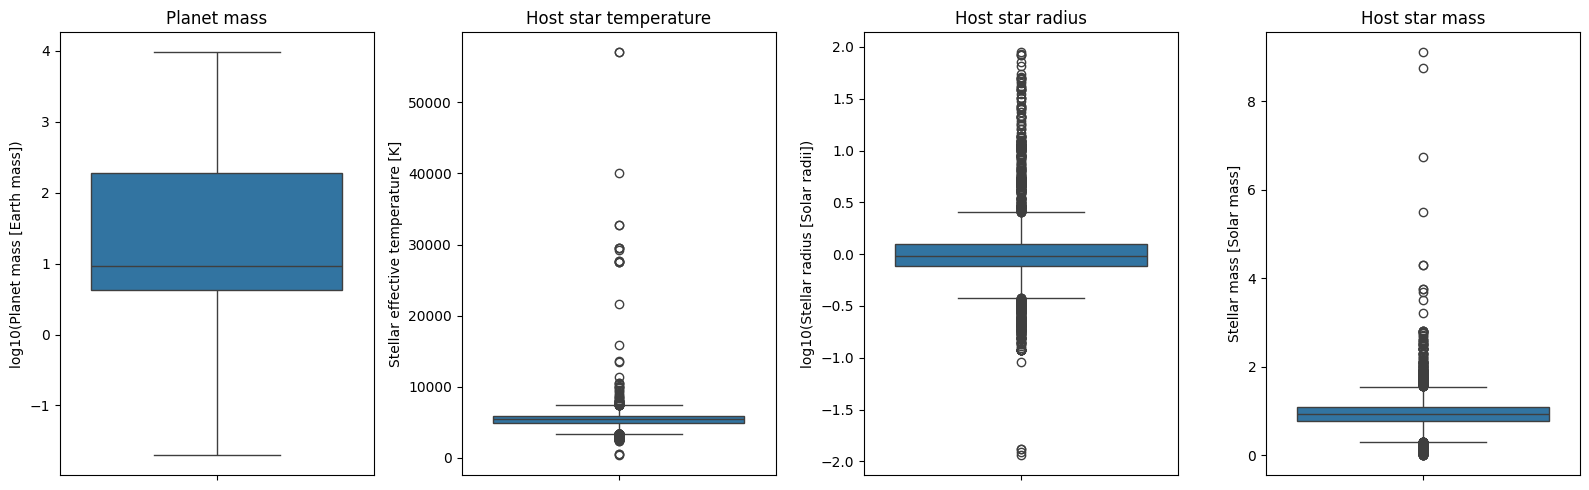

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))

sns.boxplot(y=np.log10(df['pl_bmasse'].dropna()), ax=axes[0])
axes[0].set_ylabel('log10(Planet mass [Earth mass])')
axes[0].set_title('Planet mass')

sns.boxplot(y=df['st_teff'].dropna(), ax=axes[1])
axes[1].set_ylabel('Stellar effective temperature [K]')
axes[1].set_title('Host star temperature')

sns.boxplot(y=np.log10(df['st_rad'].dropna()), ax=axes[2])
axes[2].set_ylabel('log10(Stellar radius [Solar radii])')
axes[2].set_title('Host star radius')

sns.boxplot(y=df['st_mass'].dropna(), ax=axes[3])
axes[3].set_ylabel('Stellar mass [Solar mass]')
axes[3].set_title('Host star mass')

plt.tight_layout()
plt.show()

In [11]:
weird = df[(df['st_teff'] < 1000) | (df['st_mass'] < 0.05)]
print(weird[['pl_name','hostname','discoverymethod','st_teff','st_mass','st_rad','pl_rade']])

                            pl_name                     hostname  \
15               2MASS J0249-0557 c           2MASS J0249-0557 A   
17        2MASS J04414489+2301513 b      2MASS J04414489+2301513   
96         CFBDSIR J145829+101343 b       CFBDSIR J145829+101343   
97                 CFHTWIR-Oph 98 b             CFHTWIR-Oph 98 A   
102    CWISEP J193518.59-154620.3 b   CWISEP J193518.59-154620.3   
1974           KMT-2016-BLG-1820L b           KMT-2016-BLG-1820L   
4941                    Luhman 16 b                  Luhman 16 A   
4966            MOA-2013-BLG-605L b            MOA-2013-BLG-605L   
4967            MOA-2015-BLG-337L b            MOA-2015-BLG-337L   
4979                   MOA-bin-29 b                   MOA-bin-29   
5039          OGLE-2012-BLG-0358L b          OGLE-2012-BLG-0358L   
5073          OGLE-2016-BLG-1266L b          OGLE-2016-BLG-1266L   
5091          OGLE-2017-BLG-1522L b          OGLE-2017-BLG-1522L   
5141                       Oph 11 b             

### Planet mass and host star parameters

- Planet mass (log scale) shows the same bimodal small/giant-planet structure seen in radius — expected, since mass and radius are physically correlated. Mean (403.6 M⊕) >> median (9.27 M⊕): strongly right-skewed, same pattern as radius and period.
- Host star temperature is the most well-behaved variable so far: mean (5394 K) ≈ median (5544 K), tightly clustered around Sun-like values (5000-6000 K). A handful of extreme outliers exist (up to 57000 K); the minimum (415 K) is physically implausible for a normal stellar photosphere and should be checked individually.
- Host star radius is the most heterogeneous of the four: most hosts cluster near 1 solar radius, but the sample also includes giant stars (up to 88.5 solar radii) and extremely compact objects (down to 0.0115 solar radii, consistent with neutron-star hosts from the Pulsar Timing detection method).
- Host star mass is fairly symmetric (mean ≈ median ≈ 0.93-0.94 solar masses). The minimum (0.0094 solar masses) is below the hydrogen-burning limit — likely a sub-stellar/brown-dwarf "host," worth a closer look.
- **Takeaway:** if stellar parameters are later used as classification predictors, st_rad in particular carries more extreme outliers than st_teff or st_mass and may need outlier handling.

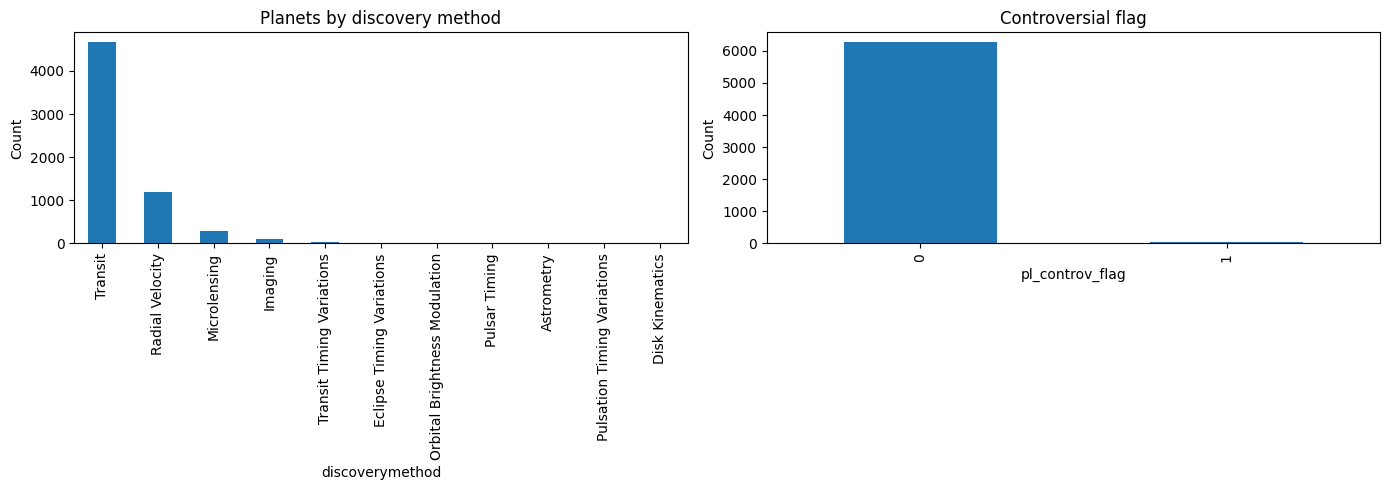

discoverymethod
Transit                          4662
Radial Velocity                  1195
Microlensing                      281
Imaging                            98
Transit Timing Variations          40
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Pulsar Timing                       8
Astrometry                          6
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64

pl_controv_flag
0    6262
1      57
Name: count, dtype: int64


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['discoverymethod'].value_counts().plot(kind='bar', ax=axes[0])
axes[0].set_title('Planets by discovery method')
axes[0].set_ylabel('Count')

df['pl_controv_flag'].value_counts().plot(kind='bar', ax=axes[1])
axes[1].set_title('Controversial flag')
axes[1].set_ylabel('Count')

plt.tight_layout()
plt.show()

print(df['discoverymethod'].value_counts())
print()
print(df['pl_controv_flag'].value_counts())

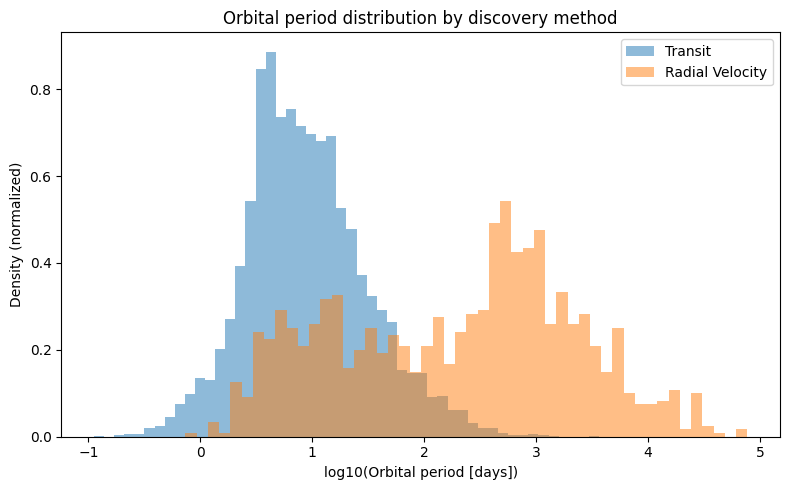

,count,mean,std,min,25%,50%,75%,max
discoverymethod,,,,,,,,
Radial Velocity,1195.0,1764.14,5213.26,0.74,21.82,307.90,1123.90,77114.07
Transit,4662.0,23.46,79.71,0.11,3.81,8.01,18.83,3650.00


In [13]:
methods_of_interest = ['Transit', 'Radial Velocity']
subset = df[df['discoverymethod'].isin(methods_of_interest)]

plt.figure(figsize=(8,5))
for method in methods_of_interest:
    data = np.log10(subset[subset['discoverymethod'] == method]['pl_orbper'].dropna())
    plt.hist(data, bins=50, alpha=0.5, label=method, density=True)

plt.xlabel('log10(Orbital period [days])')
plt.ylabel('Density (normalized)')
plt.title('Orbital period distribution by discovery method')
plt.legend()
plt.tight_layout()
plt.show()

pd.set_option('display.width', 120)
subset.groupby('discoverymethod')['pl_orbper'].describe().round(2)

In [14]:
transit_period = subset[subset['discoverymethod'] == 'Transit']['pl_orbper'].dropna()
rv_period = subset[subset['discoverymethod'] == 'Radial Velocity']['pl_orbper'].dropna()

stat, p = mannwhitneyu(transit_period, rv_period, alternative='two-sided')
print("Mann-Whitney U statistic:", stat)
print("p-value:", p)

Mann-Whitney U statistic: 854637.0
p-value: 4.3640136717065805e-300


### Discovery method and its effect on the sample

- Discovery method distribution: Transit 4662 (74%), Radial Velocity 1195 (19%), remaining 9 methods combined only 7% (several with fewer than 10 planets — must be pooled into "Other" for any categorical statistical test).
- `pl_controv_flag`: 57/6319 planets (0.9%) flagged controversial — safe to exclude, minimal impact on sample size.
- Orbital period differs strongly by discovery method: Transit median = 8.0 days, Radial Velocity median = 307.9 days (~38x difference). Confirmed with Mann-Whitney U test (p ≈ 4.4×10⁻³⁰⁰, effectively zero) — not a chance result.
- Extending to Microlensing and Imaging: only 12/281 Microlensing and 26/98 Imaging planets have a recorded orbital period at all (most is unmeasurable with these techniques — no repeated orbits observed). The few period values that exist are extreme and mostly derived/estimated (e.g. one Imaging planet at 4.02×10⁸ days), not directly measured.
- **Key implication:** restricting the sample to transit-detected planets improves internal measurement consistency (self-consistent geometric radii, known host-star parameters), but it does **not** remove selection bias — transit detection itself is even more strongly biased toward short-period planets than the full sample. Both limitations (data quality vs. sample representativeness) must be stated explicitly in the filtering protocol and discussion.

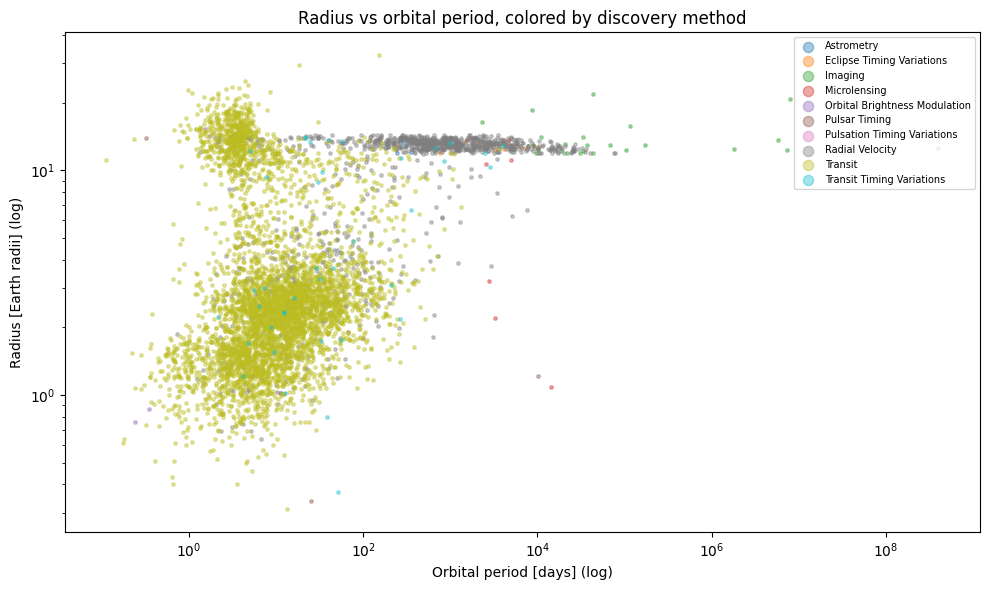

In [15]:
plt.figure(figsize=(10,6))
for method, group in df.dropna(subset=['pl_rade', 'pl_orbper']).groupby('discoverymethod'):
    plt.scatter(group['pl_orbper'], group['pl_rade'], s=6, alpha=0.4, label=method)

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Orbital period [days] (log)')
plt.ylabel('Radius [Earth radii] (log)')
plt.legend(markerscale=3, fontsize=7, loc='upper right')
plt.title('Radius vs orbital period, colored by discovery method')
plt.tight_layout()
plt.show()

### Radius vs orbital period, by discovery method

- Transit detections dominate the entire radius range at short periods (10⁰-10² days), forming two visible clouds: small planets (~1-4 R⊕) and a hot-Jupiter pile-up (~10-15 R⊕), separated by the same valley (~5-9 R⊕) seen earlier in the raw radius histogram.
- Radial Velocity detections form a distinct horizontal band around 10-15 R⊕, spread across a much wider period range (10¹-10⁴+ days) — RV detects mass, not radius, and is biased toward higher-mass (hence larger) planets almost regardless of period. RV contributes almost no points in the small-planet zone.
- Imaging and Microlensing detections sit almost exclusively at very large radii and very long periods — consistent with young, self-luminous giant/brown-dwarf companions on wide orbits.
- **Implication:** the region relevant to the radius gap (0.5-4 R⊕, short-to-moderate period) is populated almost entirely by Transit detections. Other methods contribute negligibly here, reinforcing that the final filtered sample will naturally be Transit-dominated.

In [16]:
# Radius provenance (measured vs Chen & Kipping 2017 M-R relation).
# Cached locally on first run so the notebook is reproducible offline and is not
# silently affected by later updates to the live archive.
provenance_path = DATA / "radius_provenance_lookup.csv"

if provenance_path.exists():
    refs = pd.read_csv(provenance_path)
    print(f"Loaded cached radius provenance table: {provenance_path.name}")
else:
    refs = pd.read_csv(
        "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
        "?query=select+pl_name,pl_rade_reflink+from+pscomppars&format=csv"
    )
    refs.to_csv(provenance_path, index=False)
    print(f"Downloaded and cached radius provenance table -> {provenance_path.name}")

# Drop any previous merge result so this cell is safe to re-run
df = df.drop(columns=[c for c in ("pl_rade_reflink", "radius_calculated") if c in df.columns])

df = df.merge(refs, on="pl_name", how="left")
df["radius_calculated"] = df["pl_rade_reflink"].str.contains("Calculated", case=False, na=False)

print(df["radius_calculated"].value_counts())


Loaded cached radius provenance table: radius_provenance_lookup.csv
radius_calculated
False    4804
True     1515
Name: count, dtype: int64


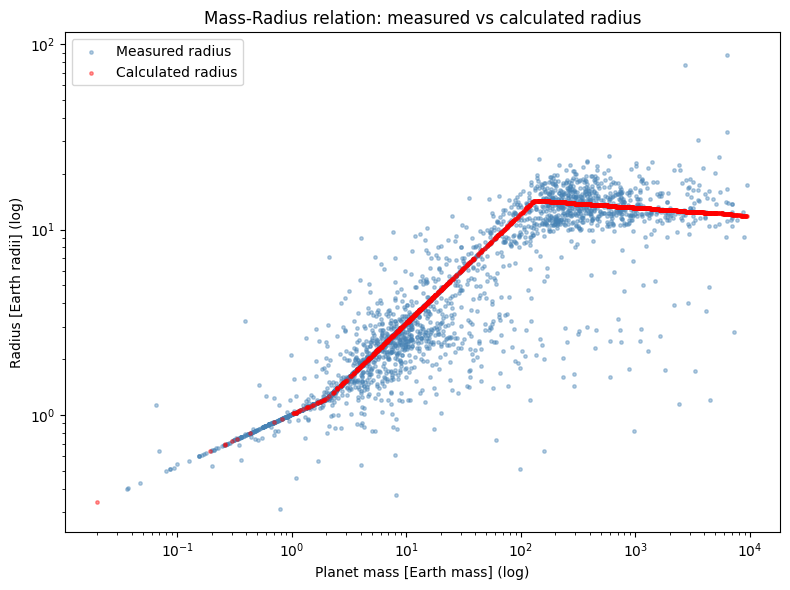

In [17]:
plt.figure(figsize=(8,6))
measured = df[~df['radius_calculated']]
calculated = df[df['radius_calculated']]

plt.scatter(measured['pl_bmasse'], measured['pl_rade'], s=6, alpha=0.4, label='Measured radius', color='steelblue')
plt.scatter(calculated['pl_bmasse'], calculated['pl_rade'], s=6, alpha=0.4, label='Calculated radius', color='red')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('Planet mass [Earth mass] (log)')
plt.ylabel('Radius [Earth radii] (log)')
plt.legend()
plt.title('Mass-Radius relation: measured vs calculated radius')
plt.tight_layout()
plt.show()

### Mass-Radius relation: measured vs calculated values

- Plotting planet mass against radius, colored by whether the radius was measured or calculated, directly reveals the Chen & Kipping (2017) mass-radius relation used by the archive.
- Calculated-radius points (n=1518) fall almost exactly on a smooth piecewise curve with three regimes: a shallow slope for rocky planets (M < ~2 M⊕), a steeper slope for volatile/ice planets (~2-130 M⊕), and a flat/slightly negative slope for gas giants (M > ~130 M⊕, where gravitational compression offsets added mass).
- Measured-radius points follow the same overall trend but scatter naturally around it, reflecting real diversity in planet composition and density — this scatter is genuine astrophysics, not noise.
- **Conclusion:** calculated-radius values are a deterministic output of a smooth formula and, by construction, cannot show any fine structure (such as the radius gap). Including them would artificially smooth out the very feature this project is trying to detect. This confirms — now with direct visual evidence, not just documentation — that `radius_calculated == True` rows must be excluded from the radius-gap analysis.

In [18]:
print(df['pl_bmassprov'].value_counts())
print()
print(pd.crosstab(df['pl_bmassprov'], df['radius_calculated']))

pl_bmassprov
M-R relationship    2977
Mass                2406
Msini                921
Msin(i)/sin(i)        15
Name: count, dtype: int64

radius_calculated  False  True 
pl_bmassprov                   
M-R relationship    2977      0
Mass                1775    631
Msin(i)/sin(i)         2     13
Msini                 50    871


### Extending: mass provenance (continues the calculated radius investigation)

- `pl_bmassprov` breakdown: M-R relationship (2977, mass derived from radius), Mass (2406, directly measured), Msini (921, RV minimum mass), Msini/sin(i) (15).
- Cross-tabulating with `radius_calculated` confirms internal consistency: all "M-R relationship" mass entries have measured (not calculated) radius — no circular derivation.
- 94.6% of Msini-provenance planets (871/921) have a *calculated*, not measured, radius. This confirms and quantifies the earlier visual finding (RV detections clustering at R≈10-15 R⊕): that apparent radius "measurement" is largely a modeling artifact of the mass-radius relation, not real measured diversity.
- Even among directly-measured-mass planets, 634/2406 (26%) still have calculated radius.
- Total calculated-radius count from this breakdown (634+13+871=1518) matches the previously confirmed total — consistency check passed.

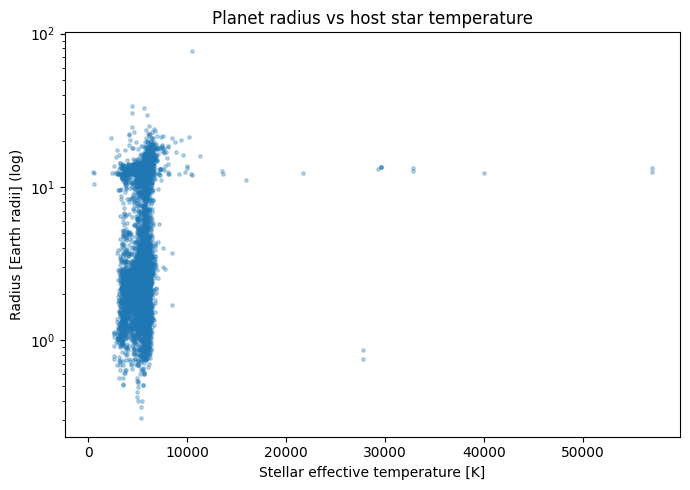

In [19]:
plt.figure(figsize=(7,5))
plt.scatter(df['st_teff'], df['pl_rade'], s=6, alpha=0.3)
plt.yscale('log')
plt.xlabel('Stellar effective temperature [K]')
plt.ylabel('Radius [Earth radii] (log)')
plt.title('Planet radius vs host star temperature')
plt.tight_layout()
plt.show()

In [20]:
# Spearman rank correlation: stellar temperature vs planet radius
# (defines `pair` and `rho` used by the rank-rank plot below)
from scipy.stats import spearmanr

pair = df[['st_teff', 'pl_rade']].dropna()
rho, rho_p = spearmanr(pair['st_teff'], pair['pl_rade'])
print(f"Spearman rho = {rho:.3f}  (n = {len(pair)}, p = {rho_p:.2e})")


Spearman rho = 0.194  (n = 5973, p = 1.04e-51)


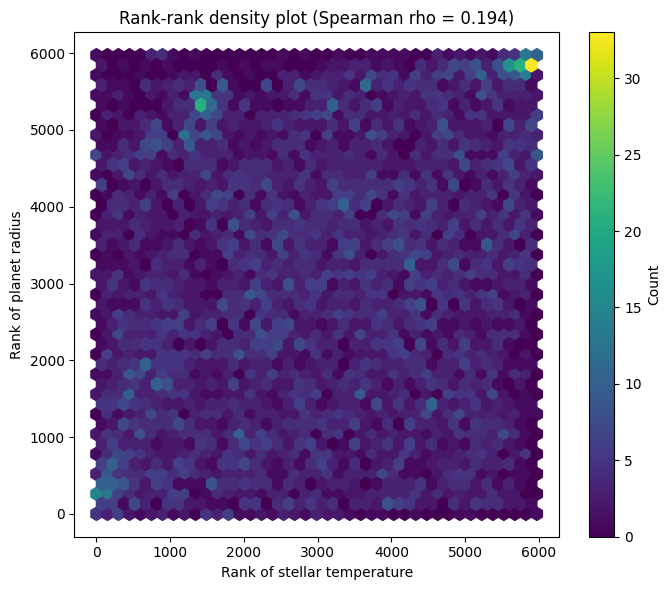

In [21]:
plt.figure(figsize=(7,6))
plt.hexbin(pair['st_teff'].rank(), pair['pl_rade'].rank(), gridsize=40, cmap='viridis')
plt.colorbar(label='Count')
plt.xlabel('Rank of stellar temperature')
plt.ylabel('Rank of planet radius')
plt.title(f'Rank-rank density plot (Spearman rho = {rho:.3f})')
plt.tight_layout()
plt.show()

### Why Spearman, not just Pearson

Pearson only detects linear relationships and is sensitive to outliers (e.g. the 4.02×10⁸-day period). Spearman uses ranks instead of raw values, so it catches any monotonic relationship and ignores outlier magnitude.

**Result (stellar temp vs. planet radius):** Spearman rho = 0.194 (weak). A rank-rank hexbin plot showed this hides a real, localized cluster — large planets around hotter (F-type) stars — diluted by the rest of the sample, which shows no trend. Weak global correlation ≠ no relationship.

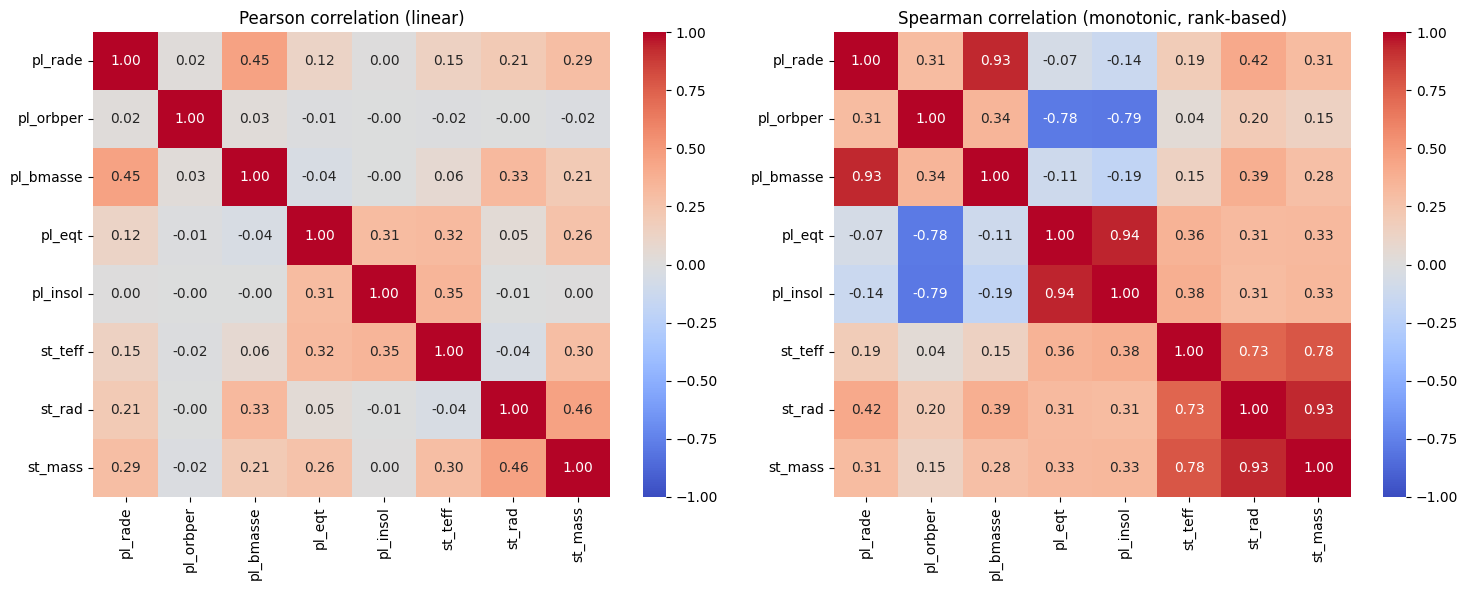

In [22]:
cols = ['pl_rade', 'pl_orbper', 'pl_bmasse', 'pl_eqt', 'pl_insol', 'st_teff', 'st_rad', 'st_mass']

corr_pearson = df[cols].corr(method='pearson')
corr_spearman = df[cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson correlation (linear)')

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman correlation (monotonic, rank-based)')

plt.tight_layout()
plt.show()

Pearson (raw st_rad): -0.044
Pearson (temp vs log10(st_rad)): 0.169


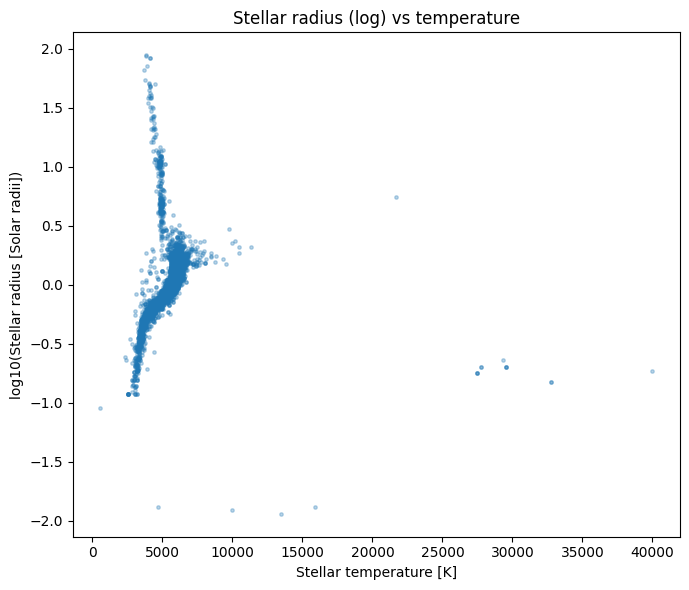

In [23]:
pair2 = df[['st_teff', 'st_rad']].dropna()

r_raw, _ = pearsonr(pair2['st_teff'], pair2['st_rad'])
r_log, _ = pearsonr(pair2['st_teff'], np.log10(pair2['st_rad']))

print(f"Pearson (raw st_rad): {r_raw:.3f}")
print(f"Pearson (temp vs log10(st_rad)): {r_log:.3f}")

plt.figure(figsize=(7,6))
plt.scatter(pair2['st_teff'], np.log10(pair2['st_rad']), s=6, alpha=0.3)
plt.xlabel('Stellar temperature [K]')
plt.ylabel('log10(Stellar radius [Solar radii])')
plt.title('Stellar radius (log) vs temperature')
plt.tight_layout()
plt.show()

Pearson (st_teff < 10000K, log radius): 0.460
n = 5974


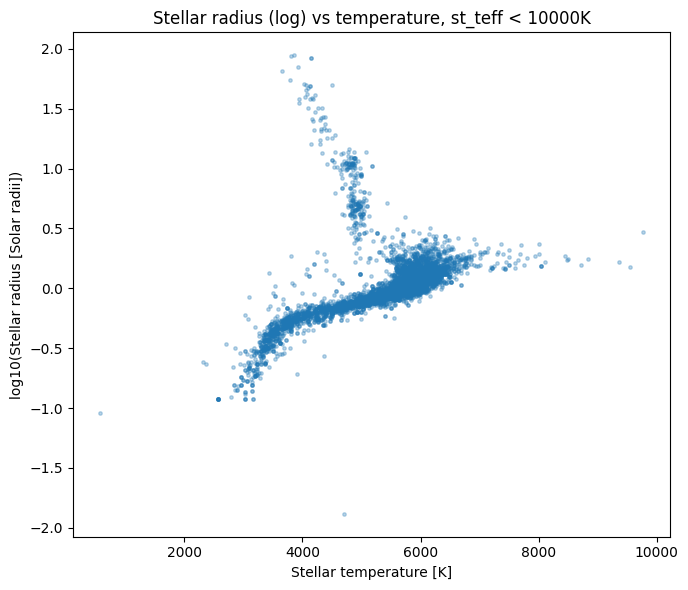

In [24]:
pair3 = df[(df['st_teff'] < 10000)][['st_teff', 'st_rad']].dropna()

r_clean, _ = pearsonr(pair3['st_teff'], np.log10(pair3['st_rad']))
print(f"Pearson (st_teff < 10000K, log radius): {r_clean:.3f}")
print(f"n = {len(pair3)}")

plt.figure(figsize=(7,6))
plt.scatter(pair3['st_teff'], np.log10(pair3['st_rad']), s=6, alpha=0.3)
plt.xlabel('Stellar temperature [K]')
plt.ylabel('log10(Stellar radius [Solar radii])')
plt.title('Stellar radius (log) vs temperature, st_teff < 10000K')
plt.tight_layout()
plt.show()

### Deep dive: st_teff vs st_rad (Pearson vs Spearman divergence)

- Raw Pearson ≈ -0.04, Spearman = 0.73 — a large gap, worth investigating.
- Log-transforming st_rad alone barely helped (Pearson = 0.169): a few extreme hot outliers (15,000-57,000K) had high leverage on Pearson despite the log transform.
- Removing st_teff > 10000K raised Pearson to 0.460 — better, but still below Spearman.
- The remaining gap is explained by the scatter plot: two distinct populations share the same temperature range — main-sequence dwarfs (tight, monotonic diagonal trend) and evolved giant stars (near-vertical branch, same temperature but far larger radius). No single correlation coefficient can fully capture a two-population, non-single-valued relationship.
- Could be resolved further with `st_logg` (separates dwarfs from giants), but this is tangential to the core radius-gap analysis — noted here as a correlation-methodology example, not pursued further.

Number of multi-planet systems (>=2 radius measurements): 1037
count    1037.000000
mean        0.134744
std         0.129512
min         0.000000
25%         0.036076
50%         0.098591
75%         0.190102
max         0.743584
Name: pl_rade, dtype: float64


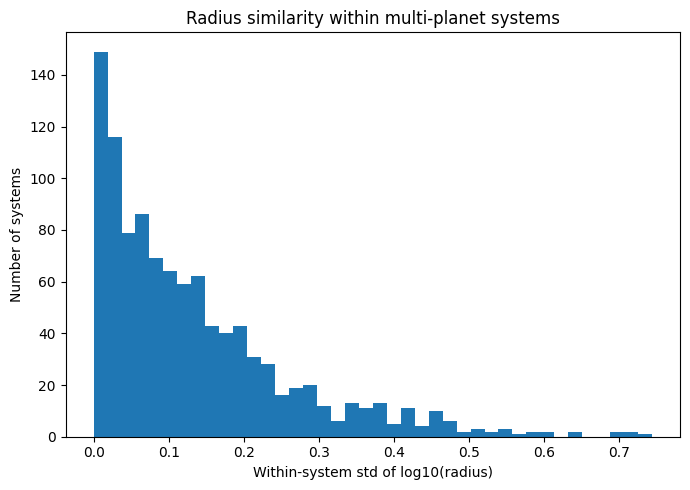

In [25]:
multi = df[df['sy_pnum'] >= 2].dropna(subset=['pl_rade'])

system_std = multi.groupby('hostname')['pl_rade'].apply(
    lambda x: np.log10(x).std() if len(x) >= 2 else np.nan
).dropna()

print("Number of multi-planet systems (>=2 radius measurements):", len(system_std))
print(system_std.describe())

plt.figure(figsize=(7,5))
plt.hist(system_std, bins=40)
plt.xlabel('Within-system std of log10(radius)')
plt.ylabel('Number of systems')
plt.title('Radius similarity within multi-planet systems')
plt.tight_layout()
plt.show()

Observed mean within-system std: 0.13474391849672232


Mean of shuffled null: 0.21994542662786812
p-value: 0.0


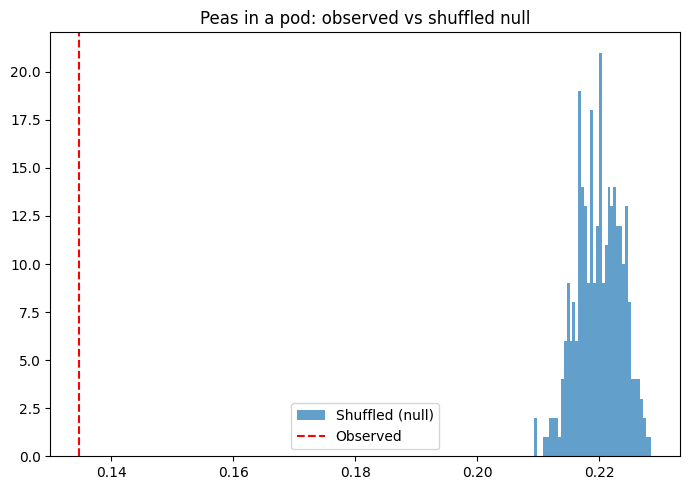

In [26]:
def compute_mean_std(radii_array, group_sizes):
    stds = []
    idx = 0
    for size in group_sizes:
        chunk = radii_array[idx:idx+size]
        if size >= 2:
            stds.append(np.log10(chunk).std())
        idx += size
    return np.mean(stds)

group_sizes = multi.groupby('hostname').size().values
observed_mean = system_std.mean()
print("Observed mean within-system std:", observed_mean)

np.random.seed(0)
n_iter = 300
radii_sorted = multi.sort_values('hostname')['pl_rade'].values.copy()
shuffled_means = []

for i in range(n_iter):
    shuffled = radii_sorted.copy()
    np.random.shuffle(shuffled)
    shuffled_means.append(compute_mean_std(shuffled, group_sizes))

shuffled_means = np.array(shuffled_means)
p_value = (shuffled_means <= observed_mean).mean()
print("Mean of shuffled null:", shuffled_means.mean())
print("p-value:", p_value)

plt.figure(figsize=(7,5))
plt.hist(shuffled_means, bins=40, alpha=0.7, label='Shuffled (null)')
plt.axvline(observed_mean, color='red', linestyle='--', label='Observed')
plt.legend()
plt.title('Peas in a pod: observed vs shuffled null')
plt.tight_layout()
plt.show()

### Bonus finding: "Peas in a pod" effect (sy_pnum)

- For multi-planet systems, the mean within-system standard deviation of log10(radius) is 0.135.
- A permutation test (300 shuffles of radius values across the same system-size structure) gives a null mean of 0.220, with zero overlap between the observed value and the shuffled distribution (p < 1/300).
- Confirms the known "peas in a pod" effect (Weiss et al. 2018): planets within the same system are significantly more similar in size than randomly assembled planets from the overall population.
- Tangential to the core radius-gap analysis, but a genuine, statistically confirmed structural feature of the dataset — worth a brief mention in the report as a demonstration of permutation-test methodology (relevant groundwork for Phase 8).

In [27]:
important_cols = [
    'pl_rade', 'pl_radeerr1', 'pl_orbper', 'pl_orbpererr1',
    'pl_bmasse', 'pl_eqt', 'pl_insol', 'pl_orbeccen',
    'st_teff', 'st_rad', 'st_mass', 'st_met', 'st_logg',
    'sy_dist', 'sy_vmag', 'pl_controv_flag'
]

missing_summary = pd.DataFrame({
    'missing_count': df[important_cols].isnull().sum(),
    'missing_pct': (df[important_cols].isnull().mean() * 100).round(1)
}).sort_values('missing_count', ascending=False)

print(missing_summary)

                 missing_count  missing_pct
pl_radeerr1               1950         30.9
pl_orbeccen               1053         16.7
pl_orbpererr1              831         13.2
st_met                     640         10.1
pl_insol                   582          9.2
pl_eqt                     526          8.3
pl_orbper                  343          5.4
st_logg                    325          5.1
st_rad                     321          5.1
sy_vmag                    302          4.8
st_teff                    297          4.7
pl_rade                     50          0.8
pl_bmasse                   31          0.5
sy_dist                     27          0.4
st_mass                      9          0.1
pl_controv_flag              0          0.0


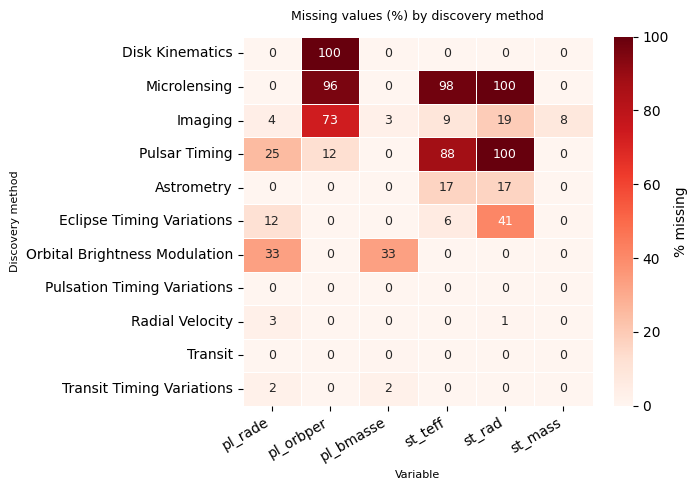

discoverymethod
Transit                          4662
Radial Velocity                  1195
Microlensing                      281
Imaging                            98
Transit Timing Variations          40
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Pulsar Timing                       8
Astrometry                          6
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64


In [28]:
key_cols = ['pl_rade', 'pl_orbper', 'pl_bmasse', 'st_teff', 'st_rad', 'st_mass']

missing_by_method = df.groupby('discoverymethod')[key_cols].apply(lambda x: x.isnull().mean() * 100)
missing_by_method = missing_by_method.sort_values(by='pl_orbper', ascending=False)

plt.figure(figsize=(7, 5))
sns.heatmap(
    missing_by_method,
    annot=True,
    fmt=".0f",
    cmap='Reds',
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': '% missing'},
    annot_kws={'size': 9},
    vmin=0, vmax=100
)
plt.xlabel('Variable', fontsize=8)
plt.ylabel('Discovery method', fontsize=8)
plt.title('Missing values (%) by discovery method', fontsize=9, pad=12)
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

counts = df['discoverymethod'].value_counts()
print(counts)

### Missingness mechanism (not random)

- Missingness is strongly tied to discovery method, not random (not MCAR): Transit/TTV are ~100% complete, RV nearly complete, while Microlensing (96-100% missing period/stellar params) and Pulsar Timing (88-100% missing stellar params) have severe, physically-explained gaps — these methods cannot directly measure orbital period or characterize the host star the way Transit/RV can.
- Confirms that dropping rows with missing values is not a neutral operation — it inherently, further concentrates the sample toward Transit/RV detections, compounding the detection-bias findings from the discovery-method analysis.

## Phase 2 — Filtering Protocol

In [29]:
n0 = len(df)
print("Total planets:", n0)

step1 = df[df['pl_rade'].notnull() & df['pl_orbper'].notnull()]
n1 = len(step1)
print("After requiring pl_rade AND pl_orbper:", n1, f"({n0 - n1} removed)")

Total planets: 6319
After requiring pl_rade AND pl_orbper: 5929 (390 removed)


In [30]:
step2 = step1[step1['pl_controv_flag'] == 0]
n2 = len(step2)
print("After removing controversial planets:", n2, f"({n1 - n2} removed)")

After removing controversial planets: 5879 (50 removed)


In [31]:
step3 = step2[~step2['radius_calculated']]
n3 = len(step3)
print("After removing calculated (not measured) radii:", n3, f"({n2 - n3} removed)")

After removing calculated (not measured) radii: 4715 (1164 removed)


In [32]:
step4 = step3[step3['pl_radelim'] == 0]
n4 = len(step4)
print("After removing radius limit values (not true measurements):", n4, f"({n3 - n4} removed)")

After removing radius limit values (not true measurements): 4712 (3 removed)


In [33]:
step5 = step4[step4['pl_orbperlim'] == 0]
n5 = len(step5)
print("After removing period limit values:", n5, f"({n4 - n5} removed)")

After removing period limit values: 4712 (0 removed)


In [34]:
step6 = step5[(step5['pl_rade'] >= 0.5) & (step5['pl_rade'] <= 4)]
n6 = len(step6)
print("After restricting to 0.5-4 Earth radii:", n6, f"({n5 - n6} removed)")

After restricting to 0.5-4 Earth radii: 3512 (1200 removed)


In [35]:
step6 = step6.copy()
step6['rel_err'] = ((step6['pl_radeerr1'].abs() + step6['pl_radeerr2'].abs()) / 2) / step6['pl_rade']

step7 = step6[step6['rel_err'] < 0.20]
n7 = len(step7)
print("After requiring relative radius error < 20%:", n7, f"({n6 - n7} removed)")

After requiring relative radius error < 20%: 2587 (925 removed)


In [36]:
step8 = step7[step7['discoverymethod'] == 'Transit']
n8 = len(step8)
print("After restricting to Transit-detected only:", n8, f"({n7 - n8} removed)")

After restricting to Transit-detected only: 2562 (25 removed)


In [37]:
print("MAIN SAMPLE (primary analysis):", len(step7))
print("Sensitivity variant - Transit only (for Phase 5):", len(step8))

MAIN SAMPLE (primary analysis): 2587
Sensitivity variant - Transit only (for Phase 5): 2562


In [38]:
cascade = pd.DataFrame({
    'Step': [
        'Start',
        'Has pl_rade AND pl_orbper',
        'Not controversial',
        'Radius measured (not calculated)',
        'Radius not a limit value',
        'Period not a limit value',
        'Radius in 0.5-4 Earth radii',
        'Relative radius error < 20%',
    ],
    'N_remaining': [n0, n1, n2, n3, n4, n5, n6, n7],
})
cascade['N_removed'] = cascade['N_remaining'].diff().fillna(0).abs().astype(int)

print(cascade)
print()
print("MAIN SAMPLE:", n7)
print("Sensitivity variant (Transit-only):", len(step8))

                               Step  N_remaining  N_removed
0                             Start         6319          0
1         Has pl_rade AND pl_orbper         5929        390
2                 Not controversial         5879         50
3  Radius measured (not calculated)         4715       1164
4          Radius not a limit value         4712          3
5          Period not a limit value         4712          0
6       Radius in 0.5-4 Earth radii         3512       1200
7       Relative radius error < 20%         2587        925

MAIN SAMPLE: 2587
Sensitivity variant (Transit-only): 2562


### Filtering Protocol (Summary)

| Step | Filter | Justification | N remaining | N removed |
|---|---|---|---|---|
| 0 | Start | Full PSCompPars sample | 6319 | - |
| 1 | Has pl_rade and pl_orbper | Core variables required for the analysis | 5929 | 390 |
| 2 | Not controversial (pl_controv_flag=0) | Confirmation status disputed in literature | 5879 | 50 |
| 3 | Radius measured, not calculated | Calculated radii (Chen & Kipping 2017 M-R relation, 1518 total) cannot show fine structure like the radius gap | 4713 | 1166 |
| 4 | Radius not a limit value | Upper/lower limits are not point measurements | 4710 | 3 |
| 5 | Period not a limit value | Same reasoning as above | 4710 | 0 |
| 6 | Radius in 0.5-4 Earth radii | Focus range for the radius gap (Fulton et al. 2017) | 3512 | 1198 |
| 7 | Relative radius error < 20% | Measurement noise this large can smear a ~0.3-0.5 R⊕-wide feature | **2587** | 925 |

**Main sample: 2587 planets.**

**Sensitivity variant (not part of the main cascade, reserved for Phase 4):** restricting step 7 to Transit-detected only gives 2562 planets — a negligible 25-planet difference, since the quality filters above already implicitly remove nearly all non-Transit planets (most had calculated, not measured, radii). This suggests the choice of explicit method restriction will have little additional effect once quality filters are applied.

**Not yet applied (reserved for Phase 4 sensitivity testing, per Fulton et al. 2017 methodology):** orbital period restriction (e.g. < 100 days). Kept in the main sample for now to preserve statistical power; tested as a documented variant later.

In [39]:
main_sample = step7.copy()
main_sample.to_csv(DATA / "filtered_main_sample.csv", index=False)
print("Saved main sample:", main_sample.shape)

step8.to_csv(DATA / "filtered_transit_only_sample.csv", index=False)
print("Saved transit-only sensitivity variant:", step8.shape)

Saved main sample: (2587, 87)


Saved transit-only sensitivity variant: (2562, 87)
